In [ ]:
!nvidia-smi

Wed May 28 02:02:43 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.133.20             Driver Version: 570.133.20     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   29C    P0             48W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

YOLOv8 can be installed in two ways - from the source and via pip. This is because it is the first iteration of YOLO to have an official package.

In [ ]:
# Pip install method (recommended)

!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 42.1/94.3 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("i-segmentation-akjbc")
version = project.version(2)
dataset = version.download("yolov8")

/content/datasets
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 64.5 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 1.16.1 requires anyio<5.0.0,>=4.8.0, but you have anyio 3.7.1 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to I-Segmentation--2 in yolov8:: 100%|██████████| 6896/6896 [00:01<00:00, 6250.33it/s]


## Custom Training

In [6]:
%cd {HOME}

!yolo task=segment mode=train model=yolov8s-seg.pt data={dataset.location}/data.yaml epochs=300 imgsz=640

/content
100% 22.8M/22.8M [00:00<00:00, 111MB/s]
New https://pypi.org/project/ultralytics/8.3.146 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
engine/trainer: task=segment, mode=train, model=yolov8s-seg.pt, data=/content/datasets/I-Segmentation--2/data.yaml, epochs=300, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=Fal

/content


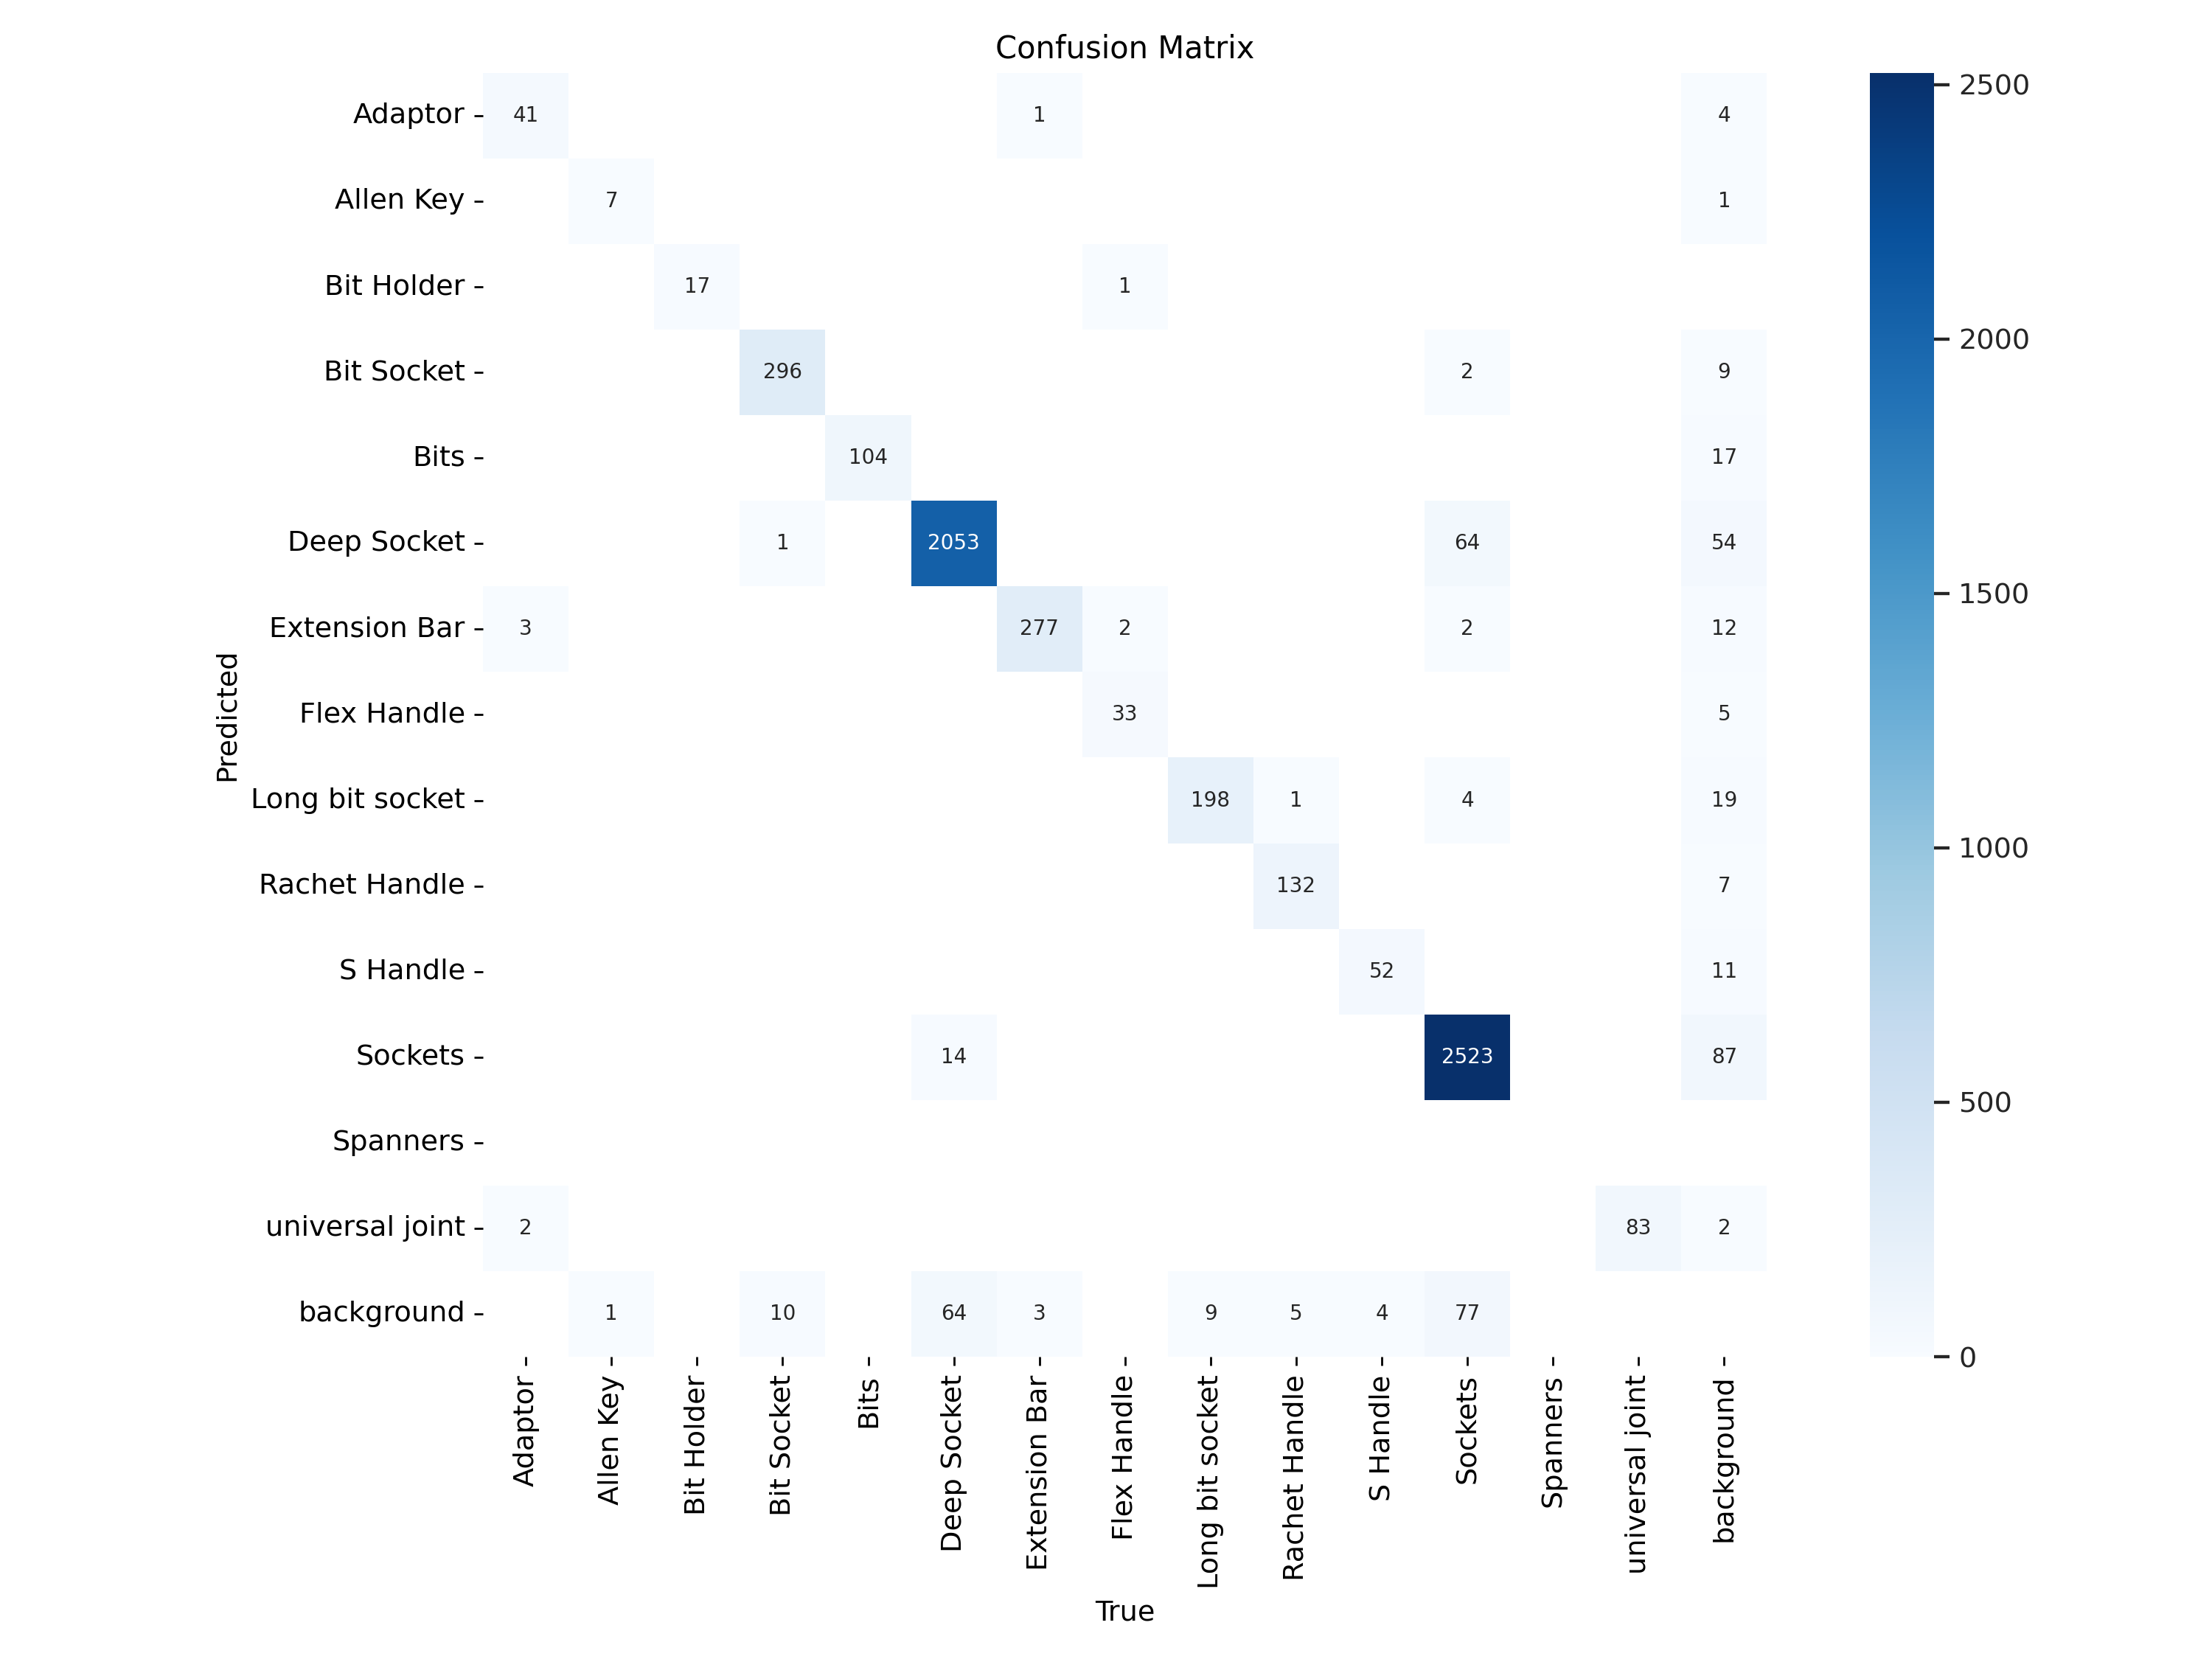

In [7]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/confusion_matrix.png', width=600)

/content


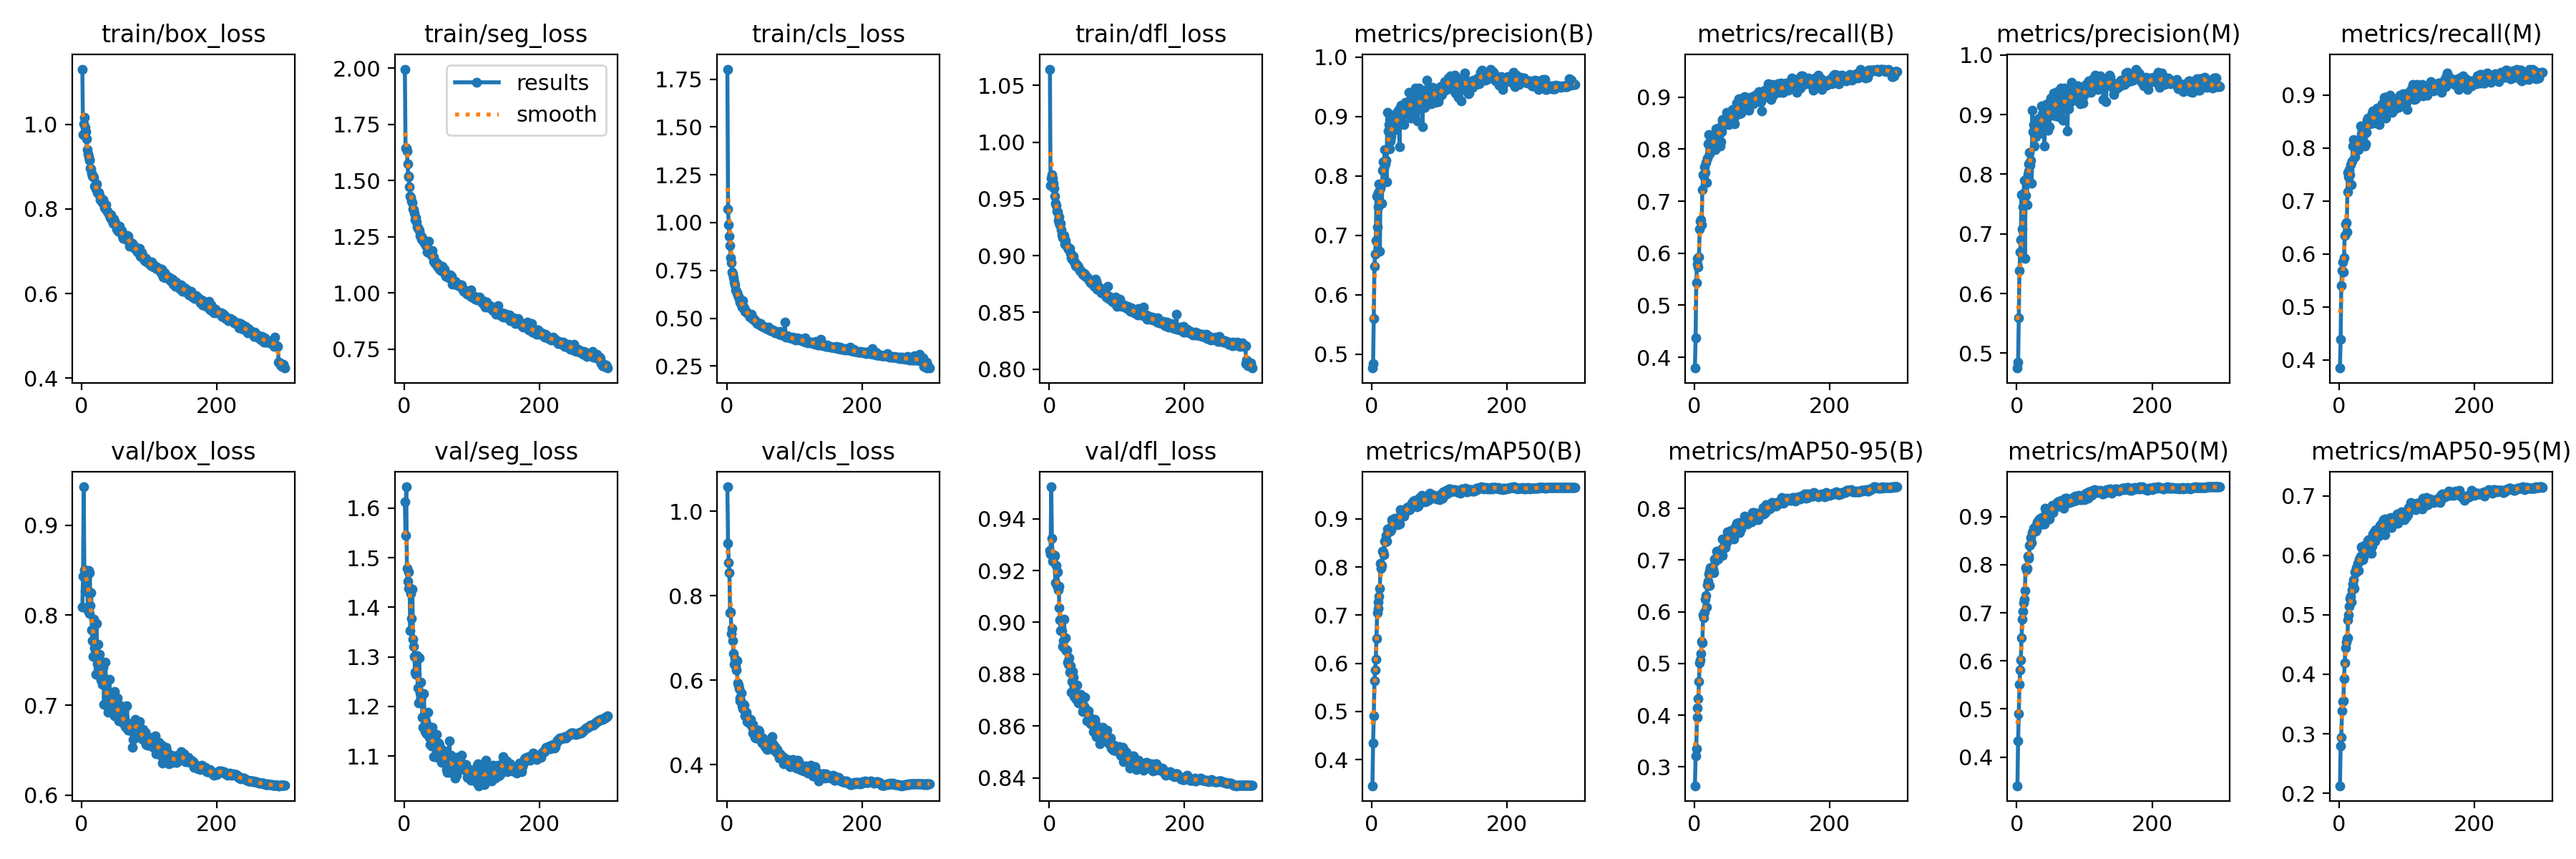

In [8]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/results.png', width=600)

/content


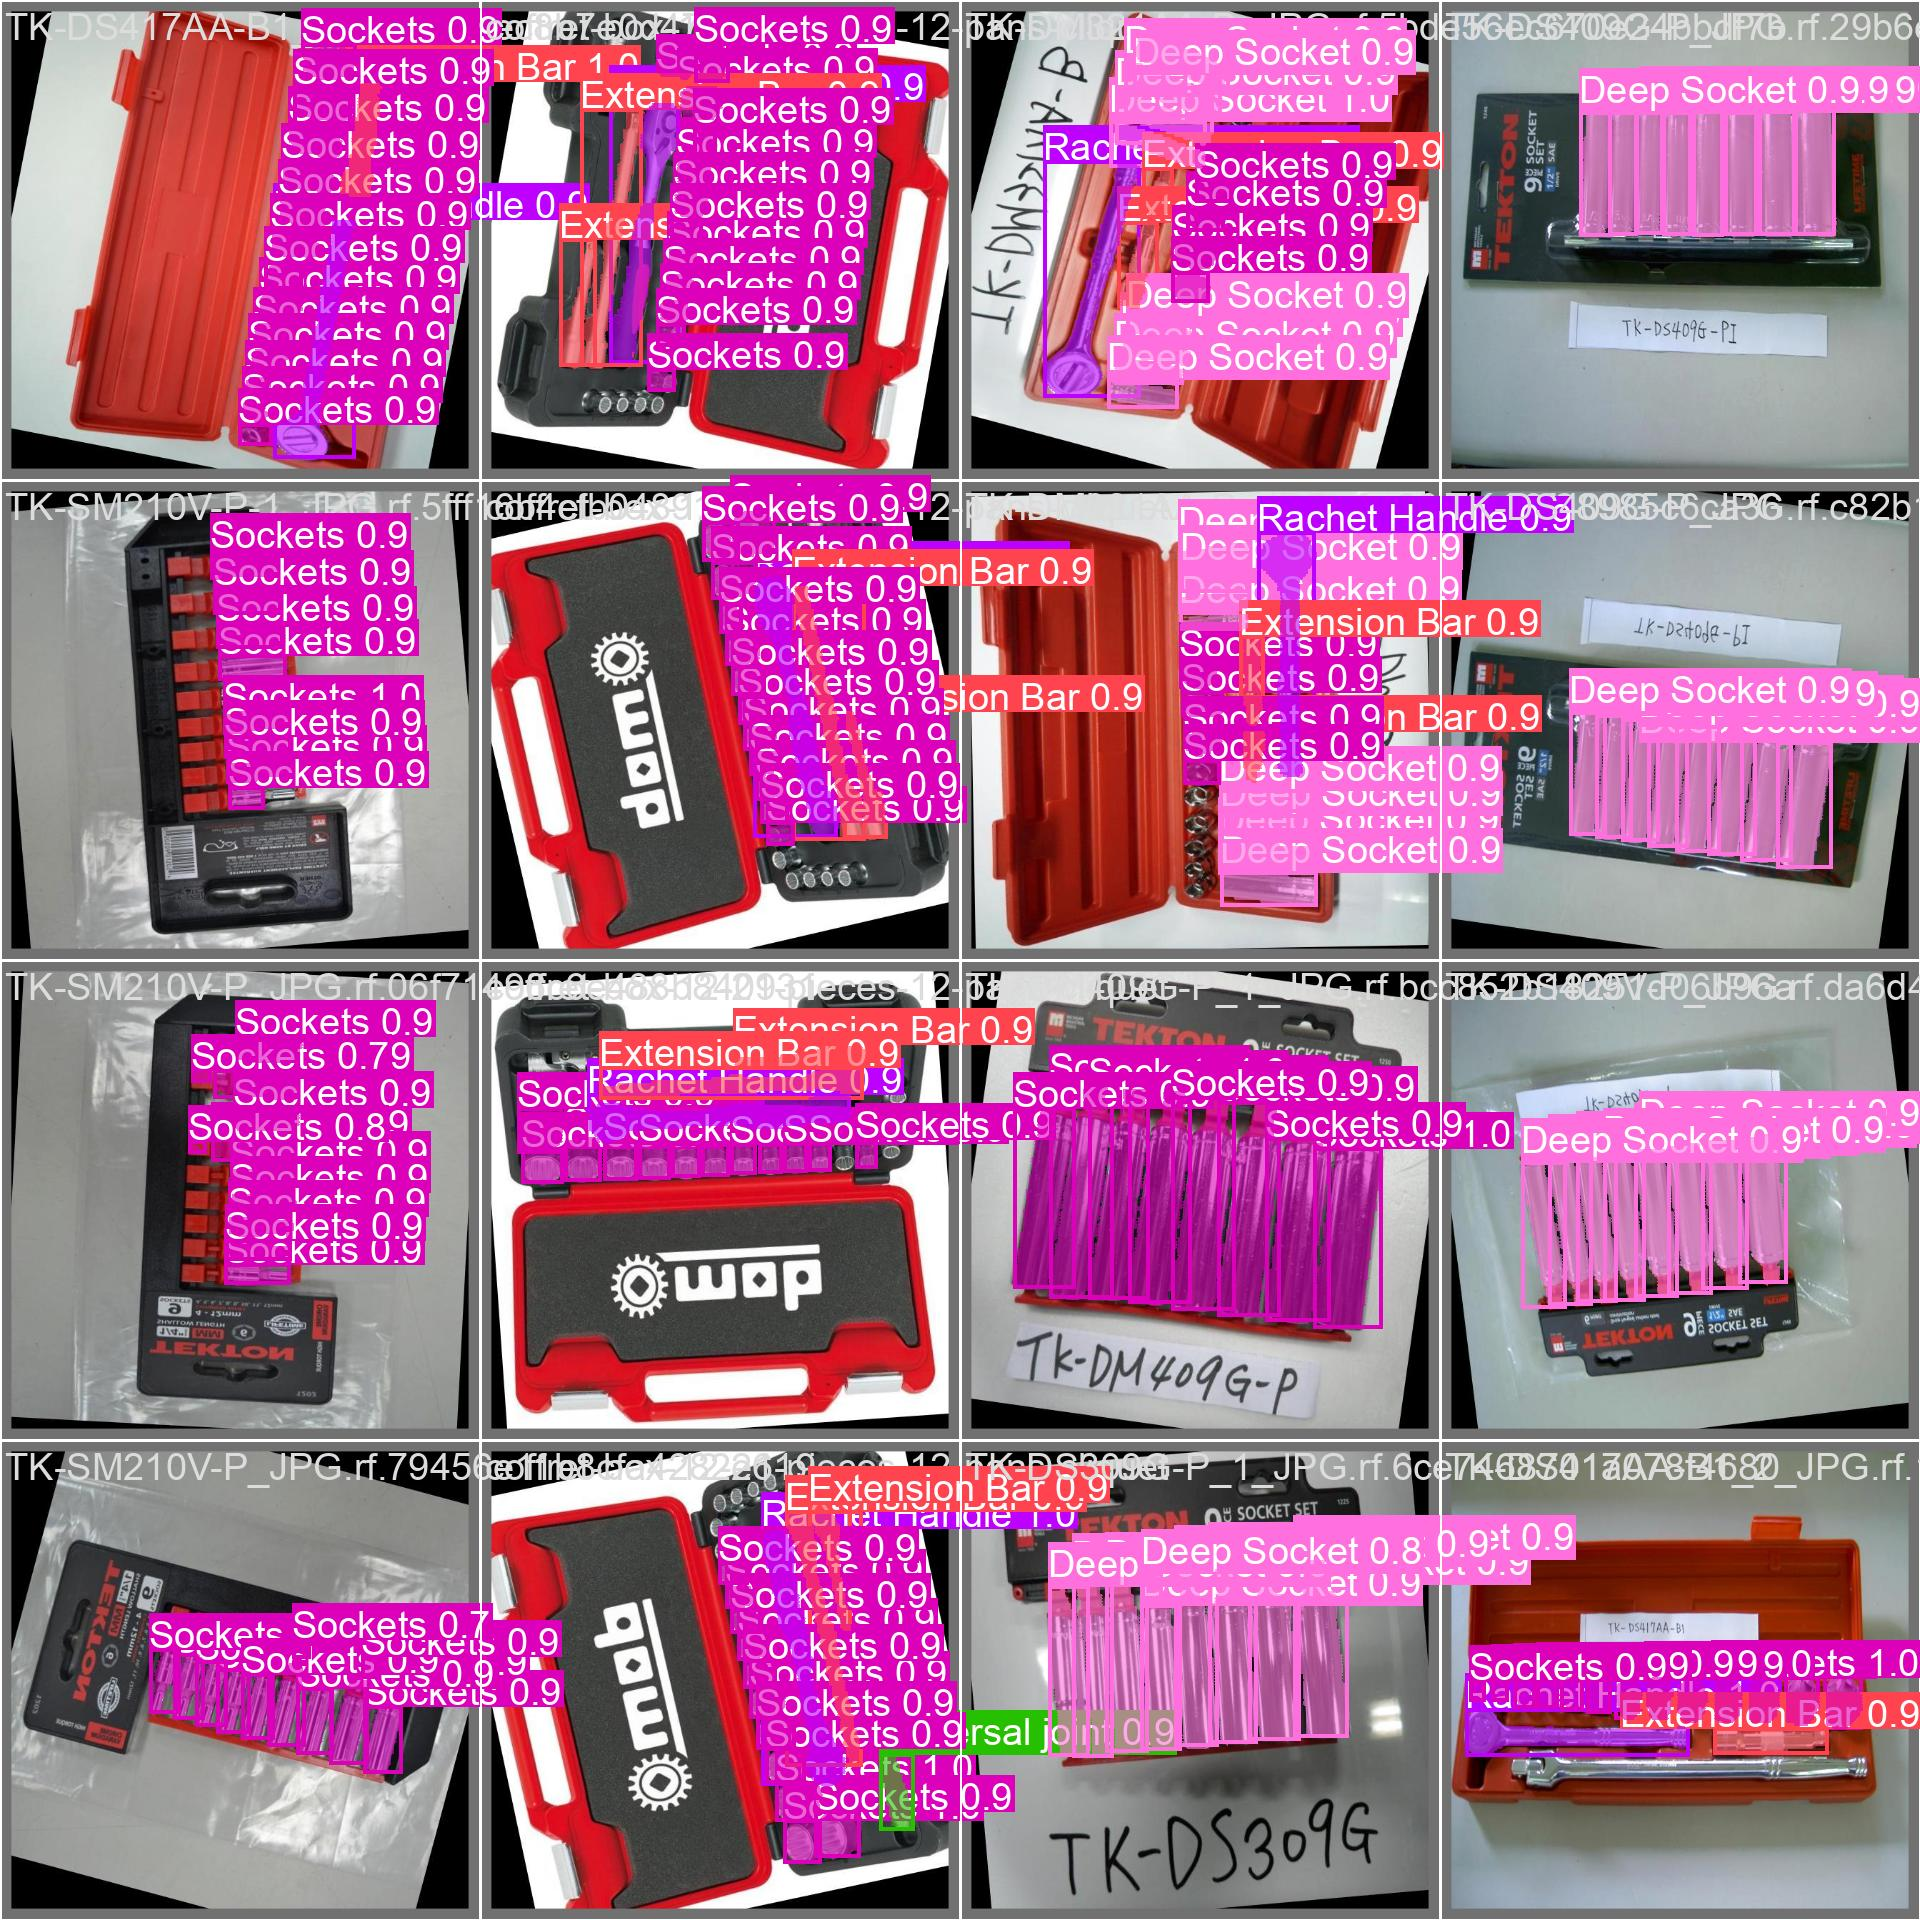

In [9]:
%cd {HOME}
Image(filename=f'{HOME}/runs/segment/train/val_batch0_pred.jpg', width=600)

## Validate Custom Model

In [10]:
%cd {HOME}

!yolo task=segment mode=val model={HOME}/runs/segment/train/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
YOLOv8s-seg summary (fused): 195 layers, 11,785,018 parameters, 0 gradients, 42.5 GFLOPs
val: Scanning /content/datasets/I-Segmentation--2/valid/labels.cache... 287 images, 0 backgrounds, 0 corrupt: 100% 287/287 [00:00<?, ?it/s]
val: WARNING ⚠️ /content/datasets/I-Segmentation--2/valid/images/96522_png.rf.054e6cde714bf1f89a760cacb7085cc7.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 18/18 [00:06<00:00,  2.85it/s]
                   all        287       6086      0.954      0.949      0.965      0.841      0.946      0.941      0.961      0.706
               Adaptor         33         46      0.975      0.865      0.931       0.78      0.975      0.864      0.931      0.587
             Allen Key          6          8      0.871      0.847       0.87     

## Inference with Custom Model

In [11]:
%cd {HOME}
!yolo task=segment mode=predict model={HOME}/runs/segment/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=true

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
YOLOv8s-seg summary (fused): 195 layers, 11,785,018 parameters, 0 gradients, 42.5 GFLOPs

image 1/146 /content/datasets/I-Segmentation--2/test/images/20240703_140727_jpg.rf.b97294895d6c696f5bc54fc1f8c6f9a5.jpg: 640x640 3 Adaptors, 1 Bit Holder, 21 Bit Sockets, 13 Deep Sockets, 3 Extension Bars, 1 Rachet Handle, 1 S Handle, 27 Socketss, 3 universal joints, 10.5ms
image 2/146 /content/datasets/I-Segmentation--2/test/images/20240703_141501_jpg.rf.6a694cef9f2e71cf1f69c292c14c2ee4.jpg: 640x640 1 Adaptor, 41 Deep Sockets, 2 Extension Bars, 34 Socketss, 2 universal joints, 9.2ms
image 3/146 /content/datasets/I-Segmentation--2/test/images/22_webp.rf.420285e59bc04a60d179f03e201c12de.jpg: 640x640 1 Allen Key, 1 Bit Holder, 1 Bits, 1 Rachet Handle, 3 S Handles, 15 Socketss, 1 universal joint, 8.7ms
image 4/146 /content/datasets/I-Segmentation--2/test/images/26_webp.rf.cedd6c9f5e23be83da5f

In [12]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/runs/segment/predict2/*.jpg')[:3]:
      display(Image(filename=image_path, height=600))
      print("\n")